### Imports

Acá importamos cosillas

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
%config InlineBackend.figure_format='retina'
import sys; print(sys.version)
sys.path.append('python-src')
from import_all_notebook_hook import *

3.8.10 (default, May 19 2021, 18:05:58) 
[GCC 7.3.0]


# Generacion de dataset de firmas

Vamos a ver como agarramos un pdf y lo transformamos en una lista de firmas. Para eso:
- `convert_from_path(pdf_path)`: nos da una lista de PNGs por hoja dado el path de un pdf.
- `preprocess_pipeline(img)`: recorta, endereza usando QR's.
- `crop_signatures(img)`: dada una imagen con una hoja de un telegrama devuelve una lista de (nombre firma, imagen firma).
- `naive_preprocess_signature`: un procesamiento naive para extraer solo la firma

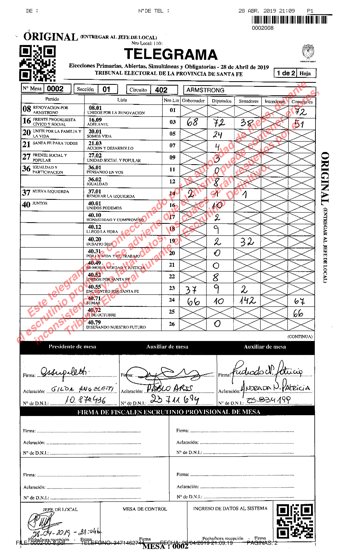

In [2]:
pdfs = convert_from_path('example.pdf')
img = pdfs[0]
resize_img(img,.2)

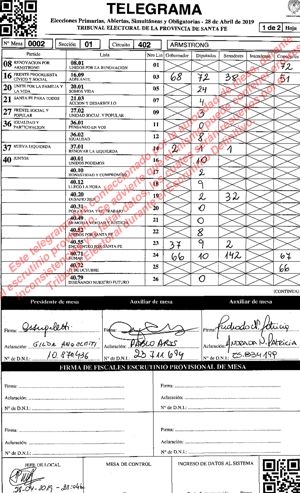

In [3]:
img = preprocess_pipeline(img)
resize_img(img,.2)

python-src/tools.py:36: MatplotlibDeprecationWarning: Passing non-integers as three-element position specification is deprecated since 3.3 and will be removed two minor releases later.
  plt.subplot((n_images+width-1)/width,width,i+1),plt.imshow(images[i],'gray')


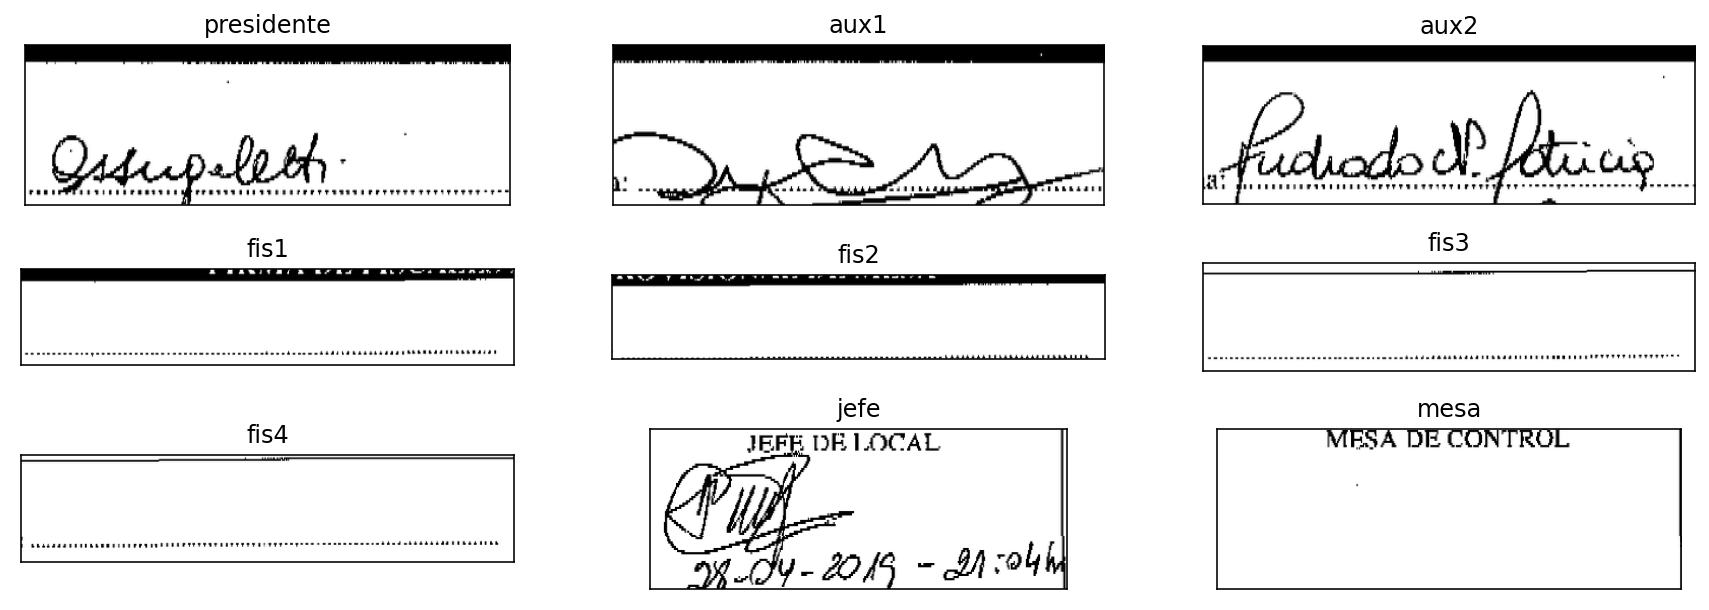

In [4]:
nombres,imgs = list(zip(*crop_signatures(img)))
plot_images_grid(imgs,3,nombres,figsize=(15,5))

python-src/telegramas_crop_signatures.py:186: FutureWarning: The new recommended value for bg_label is 0. Until version 0.19, the default bg_label value is -1. From version 0.19, the bg_label default value will be 0. To avoid this warning, please explicitly set bg_label value.
  image_label_overlay = label2rgb(blobs_labels, image=np_img)


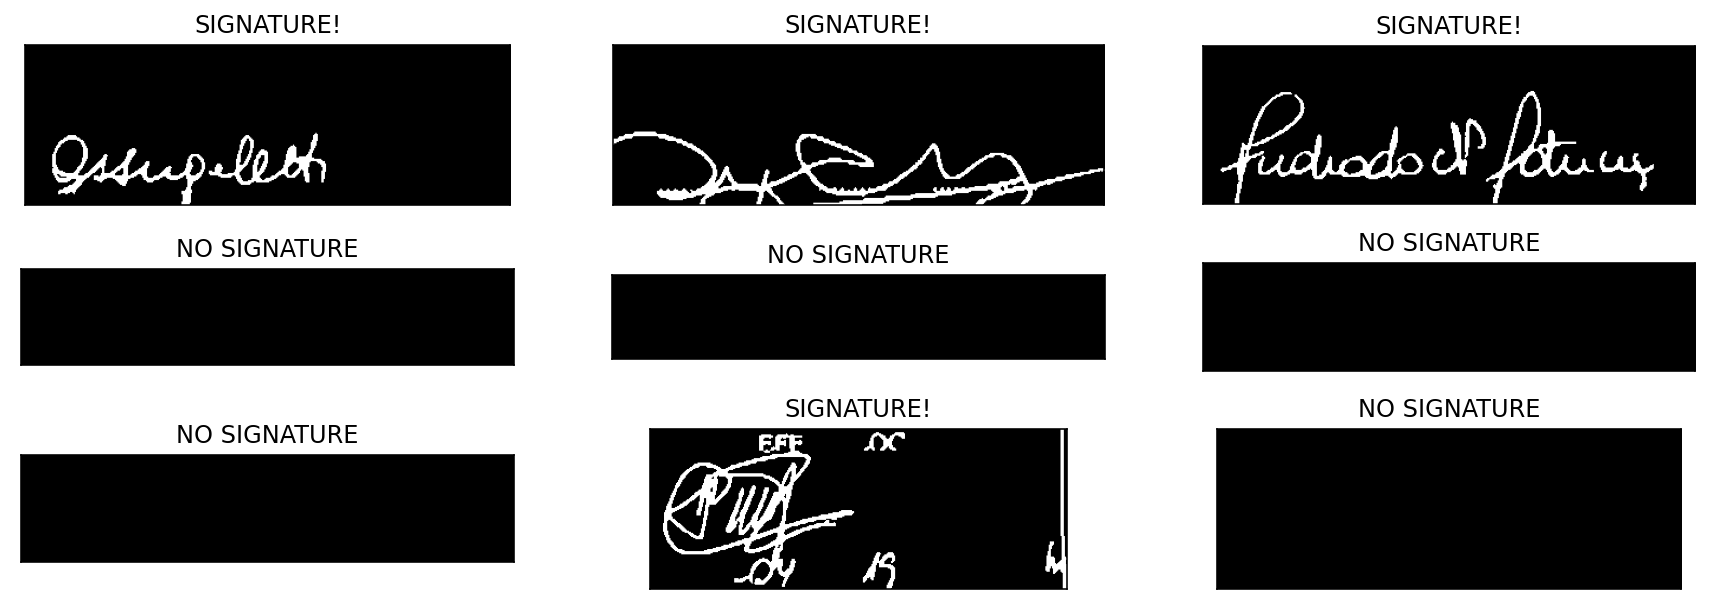

In [5]:
nombres,imgs = list(zip(*crop_signatures(img)))
proc_imgs = [Image.fromarray(naive_preprocess_signature(np.array(img))) for img in imgs]
is_sgn = ["SIGNATURE!" if naive_is_signature(img) else "NO SIGNATURE" for img in proc_imgs]
plot_images_grid(proc_imgs,3,is_sgn,figsize=(15,5))

## Procesamiento de todos los archivos

A continuación estan las funciones que leen todos los pdfs, y le aplican el pipeline anterior.

### Definicion de PATH con resultados del pipeline 

Vamos a ir procesando (paralelizando) y guardando resultados temporales.

In [2]:
# Telegramas originales (pdfs). Tiene 2 niveles de directorio. Nombres tienen pinta '5001-51-0.pdf'
TELEGRAMA_DATA_PATH = './telegramas-urn-sett'
# Telegramas como PNG (un archivo por hoja). Nombres tienen pinta 'PDF-5001-51-0-PAG-0.png'
TELEGRAMA_IMG_RAW_PATH = './telegramas-raw-data'

# PNG preprocesados
TELEGRAMA_IMG_CROP_PATH = './telegramas-crop-imgs'
# PNG que dieron error al preprocesar.
TELEGRAMA_IMG_CROP_ERROR_PATH = './telegramas-crop-imgs-error'

# PNG firmas recortadas
TELEGRAMA_SIGNATURES_PATH = './signatures'
TELEGRAMA_SIGNATURES_PATH_YES = './cls_tmp/yes-signature'
TELEGRAMA_SIGNATURES_PATH_NO = './cls_tmp/no-signature'

### Leemos los telegramas

In [7]:
telegramas_paths = list(telegramas_pdf_generator(TELEGRAMA_DATA_PATH))
print("Lodaded {} pdf's.".format(len(telegramas_paths)))
# Todos los pdf's de la carpeta ./telegramas-urn-sett/x empeizan su nombre de archivo con digito x (no hay colisiones)
assert all([os.path.basename(os.path.dirname(fp))==os.path.basename(fp)[0] for fp in telegramas_paths])
telegramas_paths[:10]

Lodaded 3559 pdf's.


['./telegramas-urn-sett/3/3984-51-2.pdf',
 './telegramas-urn-sett/3/3156-51-5.pdf',
 './telegramas-urn-sett/3/3863-52-6.pdf',
 './telegramas-urn-sett/3/3315-52-9.pdf',
 './telegramas-urn-sett/3/3157-51-9.pdf',
 './telegramas-urn-sett/3/3855-51-5.pdf',
 './telegramas-urn-sett/3/3148-51-0.pdf',
 './telegramas-urn-sett/3/3960-51-0.pdf',
 './telegramas-urn-sett/3/3175-51-7.pdf',
 './telegramas-urn-sett/3/3996-51-3.pdf']

#### Ejecutamos lo siguiente para no trabajar con todos (para una prueba por ejemplo)

In [8]:
telegramas_paths = telegramas_paths[:20]

### Convertimos los pdfs a imagenes (una imagen por hoja)

In [11]:
f_map = ctx_output_dir(apply_convert_from_path, TELEGRAMA_IMG_RAW_PATH)
imgs_fp = parallel_fmap(f_map,telegramas_paths)
imgs_fp = flatten(imgs_fp)
print("Generated {} png's.".format(len(imgs_fp)))
imgs_fp[:10]

Are you sure to delete ./telegramas-raw-data? ['yes' for yes]
yes


100%|██████████| 20/20 [00:04<00:00,  4.37it/s]

Generated 20 png's.


['./telegramas-raw-data/PDF-3984-51-2-PAG-0.png',
 './telegramas-raw-data/PDF-3156-51-5-PAG-0.png',
 './telegramas-raw-data/PDF-3863-52-6-PAG-0.png',
 './telegramas-raw-data/PDF-3315-52-9-PAG-0.png',
 './telegramas-raw-data/PDF-3157-51-9-PAG-0.png',
 './telegramas-raw-data/PDF-3855-51-5-PAG-0.png',
 './telegramas-raw-data/PDF-3148-51-0-PAG-0.png',
 './telegramas-raw-data/PDF-3960-51-0-PAG-0.png',
 './telegramas-raw-data/PDF-3175-51-7-PAG-0.png',
 './telegramas-raw-data/PDF-3996-51-3-PAG-0.png']

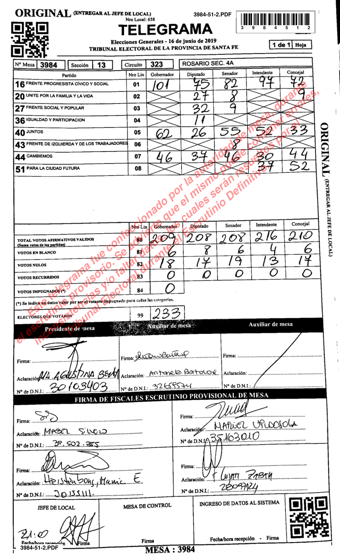

In [12]:
resize_img(Image.open(imgs_fp[0]),.2)

### Leemos los archivos png de imagen

In [13]:
raw_imgs_fp = sorted([os.path.join(TELEGRAMA_IMG_RAW_PATH,fn) for fn in os.listdir(TELEGRAMA_IMG_RAW_PATH)])
print("Lodaded {} raw png's.".format(len(raw_imgs_fp)))
raw_imgs_fp[:3]

Lodaded 20 raw png's.


['./telegramas-raw-data/PDF-3148-51-0-PAG-0.png',
 './telegramas-raw-data/PDF-3156-51-5-PAG-0.png',
 './telegramas-raw-data/PDF-3157-51-9-PAG-0.png']

### Preprocesamos las imagenes y guardamos las que generan error y los resultados

In [14]:
f_map = apply_preprocess_pipeline
f_map = ctx_output_dir(f_map, TELEGRAMA_IMG_CROP_PATH)
f_map = ctx_output_dir(f_map, TELEGRAMA_IMG_CROP_ERROR_PATH)
f_map = functools.partial(f_map, delete_origin=True)

result_paths = parallel_fmap(f_map, raw_imgs_fp)
print("Processed {} png's.".format(len(result_paths)))
result_paths[:10]

Are you sure to delete ./telegramas-crop-imgs? ['yes' for yes]
yes
Are you sure to delete ./telegramas-crop-imgs-error? ['yes' for yes]
yes


100%|██████████| 20/20 [00:10<00:00,  1.97it/s]

Processed 20 png's.


['./telegramas-crop-imgs-error/PDF-3148-51-0-PAG-0.png',
 './telegramas-crop-imgs/PDF-3156-51-5-PAG-0.png',
 './telegramas-crop-imgs/PDF-3157-51-9-PAG-0.png',
 './telegramas-crop-imgs/PDF-3174-51-3-PAG-0.png',
 './telegramas-crop-imgs/PDF-3175-51-7-PAG-0.png',
 './telegramas-crop-imgs/PDF-3302-51-8-PAG-0.png',
 './telegramas-crop-imgs/PDF-3315-52-9-PAG-0.png',
 './telegramas-crop-imgs/PDF-3756-51-7-PAG-0.png',
 './telegramas-crop-imgs/PDF-3793-51-7-PAG-0.png',
 './telegramas-crop-imgs/PDF-3812-51-1-PAG-0.png']

### Una que generó error la mostramos y vemos el error que genera

El error es que solo encuentra 1 QR. Vamos a ignorar las hojas que den errores. Muchos de estos errores no nos van a llegar (si no se detecta un QR se arrojará un error antes)

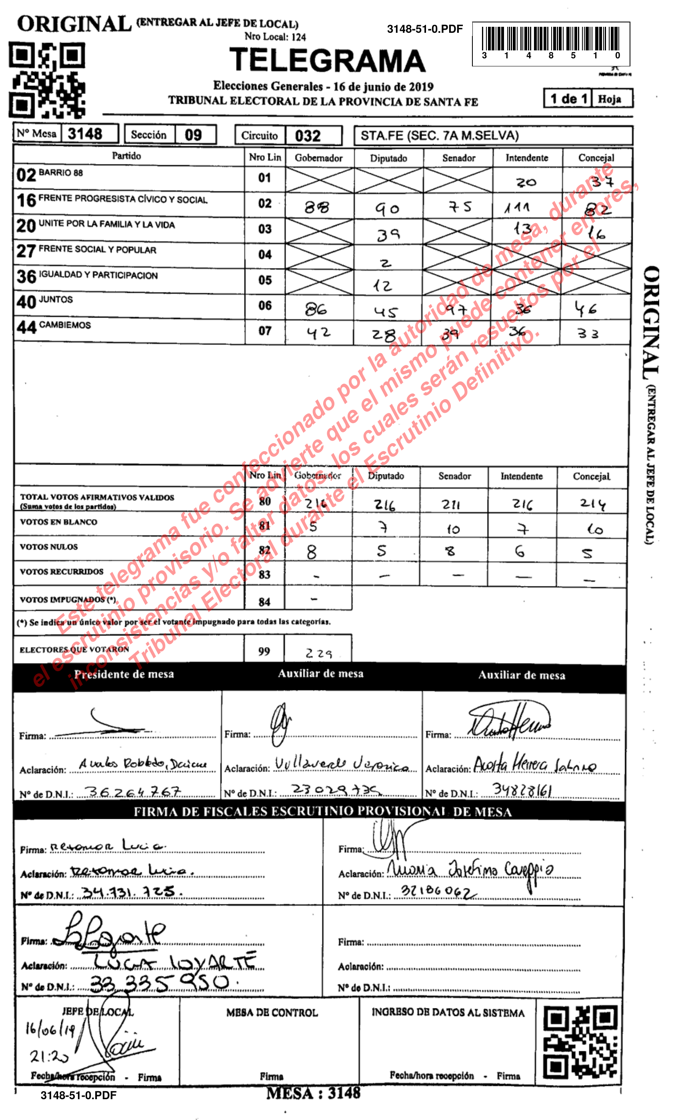

In [16]:
img = Image.open('./telegramas-crop-imgs-error/PDF-3148-51-0-PAG-0.png')
resize_img(img,.4)

In [17]:
img = preprocess_pipeline(img)

Exception: Only 1 QR code detected: [Decoded(data=b'31480110', type='QRCODE', rect=Rect(left=23, top=115, width=193, height=192), polygon=[Point(x=23, y=115), Point(x=25, y=305), Point(x=216, y=307), Point(x=212, y=117)])]

### Leemos los PNGs preprocesados

In [18]:
preproc_imgs_fp = sorted([os.path.join(TELEGRAMA_IMG_CROP_PATH,fn) for fn in os.listdir(TELEGRAMA_IMG_CROP_PATH)])
print("Lodaded {} preprocessed png's.".format(len(preproc_imgs_fp)))
preproc_imgs_fp

Lodaded 19 preprocessed png's.


['./telegramas-crop-imgs/PDF-3156-51-5-PAG-0.png',
 './telegramas-crop-imgs/PDF-3157-51-9-PAG-0.png',
 './telegramas-crop-imgs/PDF-3174-51-3-PAG-0.png',
 './telegramas-crop-imgs/PDF-3175-51-7-PAG-0.png',
 './telegramas-crop-imgs/PDF-3302-51-8-PAG-0.png',
 './telegramas-crop-imgs/PDF-3315-52-9-PAG-0.png',
 './telegramas-crop-imgs/PDF-3756-51-7-PAG-0.png',
 './telegramas-crop-imgs/PDF-3793-51-7-PAG-0.png',
 './telegramas-crop-imgs/PDF-3812-51-1-PAG-0.png',
 './telegramas-crop-imgs/PDF-3842-51-0-PAG-0.png',
 './telegramas-crop-imgs/PDF-3846-51-6-PAG-0.png',
 './telegramas-crop-imgs/PDF-3855-51-5-PAG-0.png',
 './telegramas-crop-imgs/PDF-3863-52-6-PAG-0.png',
 './telegramas-crop-imgs/PDF-3936-54-3-PAG-0.png',
 './telegramas-crop-imgs/PDF-3960-51-0-PAG-0.png',
 './telegramas-crop-imgs/PDF-3972-52-7-PAG-0.png',
 './telegramas-crop-imgs/PDF-3984-51-2-PAG-0.png',
 './telegramas-crop-imgs/PDF-3992-51-7-PAG-0.png',
 './telegramas-crop-imgs/PDF-3996-51-3-PAG-0.png']

### Recortamos las firmas de cada pagina de telegrama y guardamos

In [19]:
f_map = ctx_output_dir(apply_crop_signatures, TELEGRAMA_SIGNATURES_PATH)
f_map = functools.partial(f_map, delete_origin=False)

signature_paths = parallel_fmap(f_map, preproc_imgs_fp)
signature_paths = flatten(signature_paths)
print("Processed {} png's.".format(len(signature_paths)))
signature_paths[:10]

Are you sure to delete ./signatures? ['yes' for yes]
yes


100%|██████████| 19/19 [00:00<00:00, 27.54it/s]

Processed 171 png's.


['./signatures/PDF-3156-51-5-PAG-0-presidente.PNG',
 './signatures/PDF-3156-51-5-PAG-0-aux1.PNG',
 './signatures/PDF-3156-51-5-PAG-0-aux2.PNG',
 './signatures/PDF-3156-51-5-PAG-0-fis1.PNG',
 './signatures/PDF-3156-51-5-PAG-0-fis2.PNG',
 './signatures/PDF-3156-51-5-PAG-0-fis3.PNG',
 './signatures/PDF-3156-51-5-PAG-0-fis4.PNG',
 './signatures/PDF-3156-51-5-PAG-0-jefe.PNG',
 './signatures/PDF-3156-51-5-PAG-0-mesa.PNG',
 './signatures/PDF-3157-51-9-PAG-0-presidente.PNG']

### Leemos el directorio con todas las firmas

In [3]:
signature_paths = sorted([os.path.join(TELEGRAMA_SIGNATURES_PATH,fn) for fn in os.listdir(TELEGRAMA_SIGNATURES_PATH)])
print("Lodaded {} signatures".format(len(signature_paths)))
signature_paths[:10]

Lodaded 171 preprocessed png's.


['./signatures/PDF-3156-51-5-PAG-0-aux1.PNG',
 './signatures/PDF-3156-51-5-PAG-0-aux2.PNG',
 './signatures/PDF-3156-51-5-PAG-0-fis1.PNG',
 './signatures/PDF-3156-51-5-PAG-0-fis2.PNG',
 './signatures/PDF-3156-51-5-PAG-0-fis3.PNG',
 './signatures/PDF-3156-51-5-PAG-0-fis4.PNG',
 './signatures/PDF-3156-51-5-PAG-0-jefe.PNG',
 './signatures/PDF-3156-51-5-PAG-0-mesa.PNG',
 './signatures/PDF-3156-51-5-PAG-0-presidente.PNG',
 './signatures/PDF-3157-51-9-PAG-0-aux1.PNG']

### Aqui un ejemplo de firmas y su procesamiento/clasificacion naive

python-src/telegramas_crop_signatures.py:186: FutureWarning: The new recommended value for bg_label is 0. Until version 0.19, the default bg_label value is -1. From version 0.19, the bg_label default value will be 0. To avoid this warning, please explicitly set bg_label value.
  image_label_overlay = label2rgb(blobs_labels, image=np_img)
python-src/tools.py:35: MatplotlibDeprecationWarning: Passing non-integers as three-element position specification is deprecated since 3.3 and will be removed two minor releases later.
  plt.subplot((n_images+width-1)/width,width,i+1),plt.imshow(images[i],'gray')


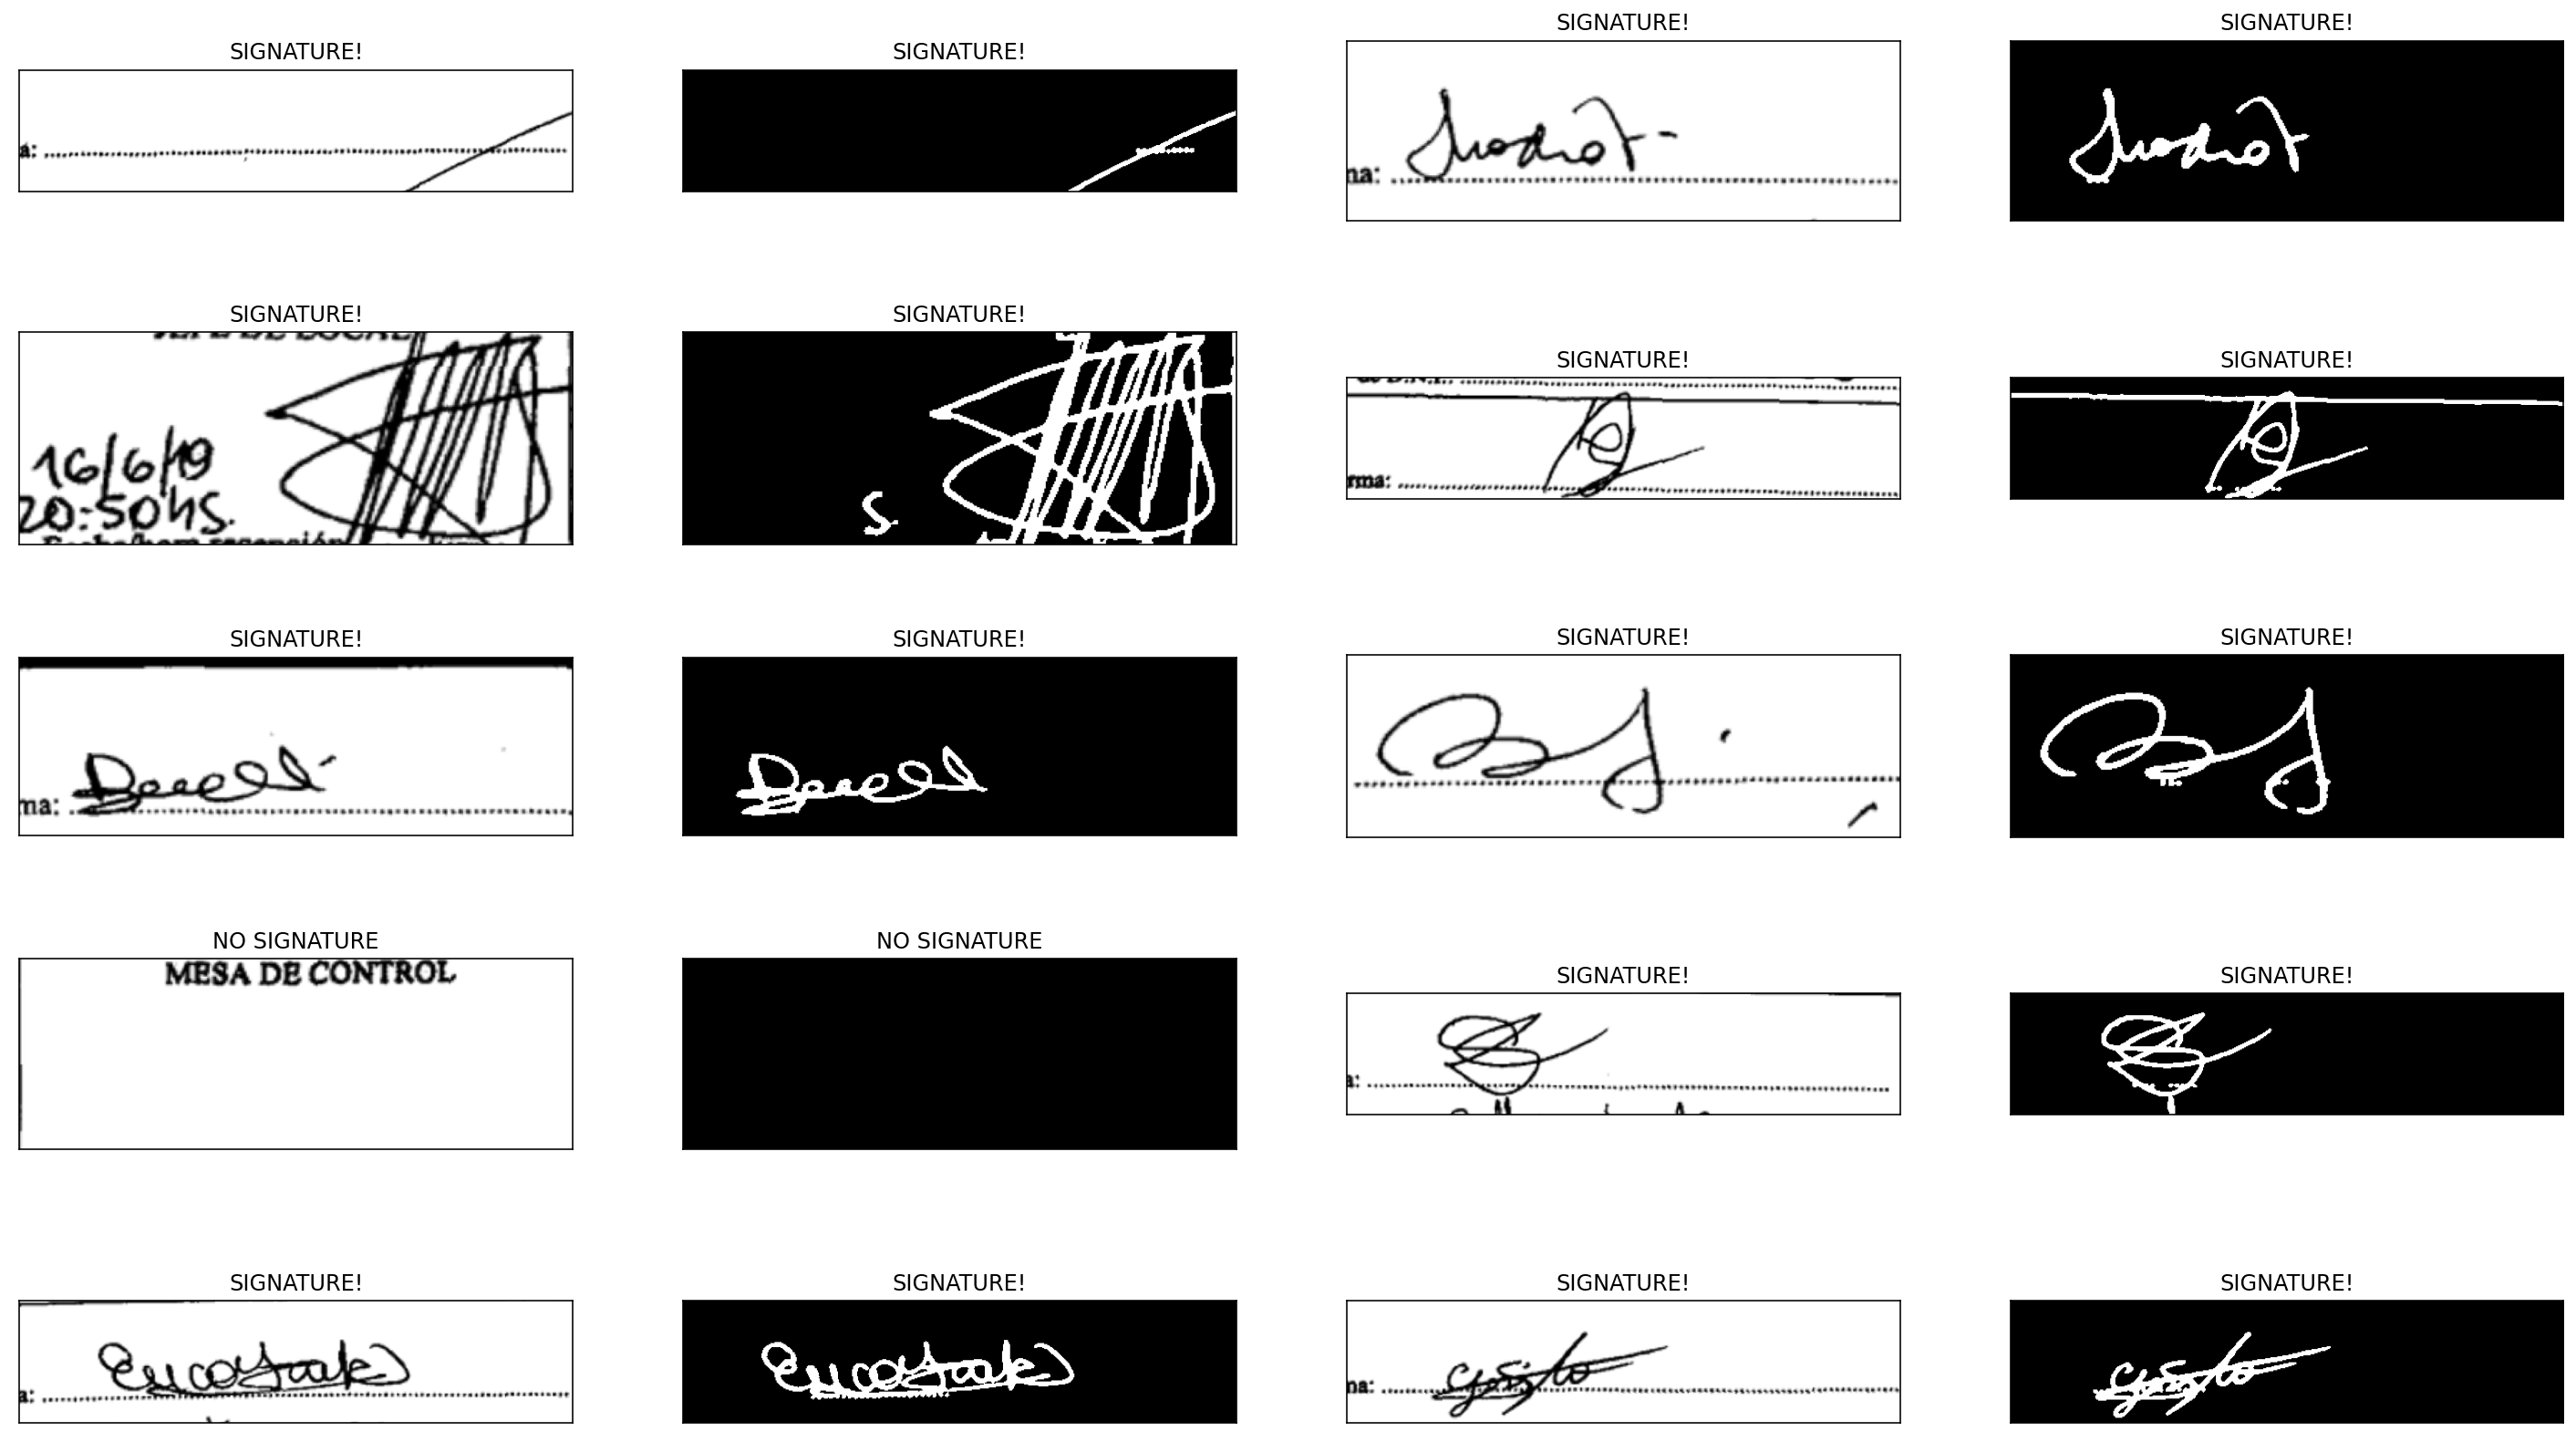

In [4]:
N_SAMPLE = 10

imgs = [ Image.open(fp) for fp in random.sample(signature_paths, N_SAMPLE) ]
proc_imgs = [ Image.fromarray(naive_preprocess_signature(np.array(img))) for img in imgs ]
cls = ["SIGNATURE!" if naive_is_signature(img) else "NO SIGNATURE" for img in proc_imgs]

images = flatten(list(zip(imgs,proc_imgs)))
titles = flatten(list(zip(cls,cls)))


plot_images_grid(images,4,titles,figsize=(25,15))

### Clasificamos las firmas y guardamos en dos directorios

In [5]:
f_map = apply_cls_signatures
f_map = ctx_output_dir(f_map, TELEGRAMA_SIGNATURES_PATH_YES)
f_map = ctx_output_dir(f_map, TELEGRAMA_SIGNATURES_PATH_NO)

result_paths = parallel_fmap(f_map, signature_paths)
print("Classified {} signatures.".format(len(result_paths)))
result_paths[:10]

Are you sure to delete ./cls_tmp/yes-signature? ['yes' for yes]
yes
Are you sure to delete ./cls_tmp/no-signature? ['yes' for yes]
yes


100%|██████████| 171/171 [00:02<00:00, 83.34it/s]


Processed 171 png's.


['./cls_tmp/yes-signature/PDF-3156-51-5-PAG-0-aux1.PNG',
 './cls_tmp/yes-signature/PDF-3156-51-5-PAG-0-aux2.PNG',
 './cls_tmp/yes-signature/PDF-3156-51-5-PAG-0-fis1.PNG',
 './cls_tmp/yes-signature/PDF-3156-51-5-PAG-0-fis2.PNG',
 './cls_tmp/yes-signature/PDF-3156-51-5-PAG-0-fis3.PNG',
 './cls_tmp/no-signature/PDF-3156-51-5-PAG-0-fis4.PNG',
 './cls_tmp/yes-signature/PDF-3156-51-5-PAG-0-jefe.PNG',
 './cls_tmp/no-signature/PDF-3156-51-5-PAG-0-mesa.PNG',
 './cls_tmp/yes-signature/PDF-3156-51-5-PAG-0-presidente.PNG',
 './cls_tmp/yes-signature/PDF-3157-51-9-PAG-0-aux1.PNG']

In [4]:
import fastbook
fastbook.setup_book()
from fastbook import *

ModuleNotFoundError: No module named 'fastbook'

In [3]:
get_images('./cls_test')

NameError: name 'get_images' is not defined